# Value at Risk (VaR) d'un portefeuille d'actions suisses

**Question :** quelle perte quotidienne peut-on attendre, dans 95 % des cas, sur un portefeuille de 1 000 000 CHF investi dans 10 grandes valeurs suisses du SMI ?

La **VaR à 95 %** est le seuil de perte qui n'est dépassé que 5 % des jours. On la calcule ici de deux façons :
- **historique** : directement à partir des rendements observés ;
- **paramétrique** : en supposant que les rendements suivent une loi normale.

Période étudiée : août 2019 - août 2021 (crise du COVID-19 incluse).

> Projet pédagogique - ne constitue pas un conseil en investissement.

## 1. Paramètres

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

plt.rcParams['figure.figsize'] = (11, 5)

MONTANT = 1_000_000   # montant investi en CHF
CONFIANCE = 0.95      # niveau de confiance de la VaR
DEBUT, FIN = '2019-08-30', '2021-08-27'

# ticker -> poids dans le portefeuille
# ticker Yahoo Finance (.SW = SIX Swiss Exchange)
portefeuille = {
    'NESN.SW': 0.15,   # Nestlé (alimentation)
    'NOVN.SW': 0.15,   # Novartis (pharmacie)
    'RO.SW':   0.15,   # Roche (pharmacie)
    'UBSG.SW': 0.10,   # UBS (banque)
    'ZURN.SW': 0.10,   # Zurich Insurance (assurance)
    'ABBN.SW': 0.10,   # ABB (industrie)
    'CFR.SW':  0.10,   # Richemont (luxe)
    'LONN.SW': 0.05,   # Lonza (biotechnologie)
    'SREN.SW': 0.05,   # Swiss Re (réassurance)
    'GIVN.SW': 0.05,   # Givaudan (arômes et parfums)
}
poids = pd.Series(portefeuille)
print(f"Somme des poids : {poids.sum():.0%}")

Somme des poids : 100%


## 2. Téléchargement des cours

Les cours viennent de Yahoo Finance. Une copie est enregistrée dans `data/prices.csv` et réutilisée si Yahoo est inaccessible.

In [2]:
FICHIER = 'data/prices.csv'

cours = yf.download(list(portefeuille), start=DEBUT, end=FIN, auto_adjust=True, progress=False)['Close'].dropna()
if cours.empty:
    print("Yahoo inaccessible -> lecture de la copie locale")
    cours = pd.read_csv(FICHIER, index_col=0, parse_dates=True)
else:
    os.makedirs('data', exist_ok=True)
    cours.to_csv(FICHIER)

cours = cours[poids.index]
cours.tail()

Ticker,NESN.SW,NOVN.SW,RO.SW,UBSG.SW,ZURN.SW,ABBN.SW,CFR.SW,LONN.SW,SREN.SW,GIVN.SW
Date,,,,,,,,,,
2021-08-20,99.629250,67.029121,346.279755,12.976665,310.834961,29.549500,84.968193,735.207520,61.992996,4174.095215
2021-08-23,99.458099,67.421242,347.814240,13.040652,312.214447,29.704119,88.186691,739.449402,62.676003,4208.390137
2021-08-24,99.235603,66.284088,345.597778,13.100373,311.754608,29.738478,88.916214,741.377563,62.966629,4179.510254
2021-08-25,98.448288,65.735123,342.528809,13.249677,310.068634,29.300390,88.830383,740.992004,62.734116,4146.117676
2021-08-26,98.893295,66.064514,346.961731,13.177158,308.612579,29.497959,88.916214,736.557190,62.458008,4150.629883


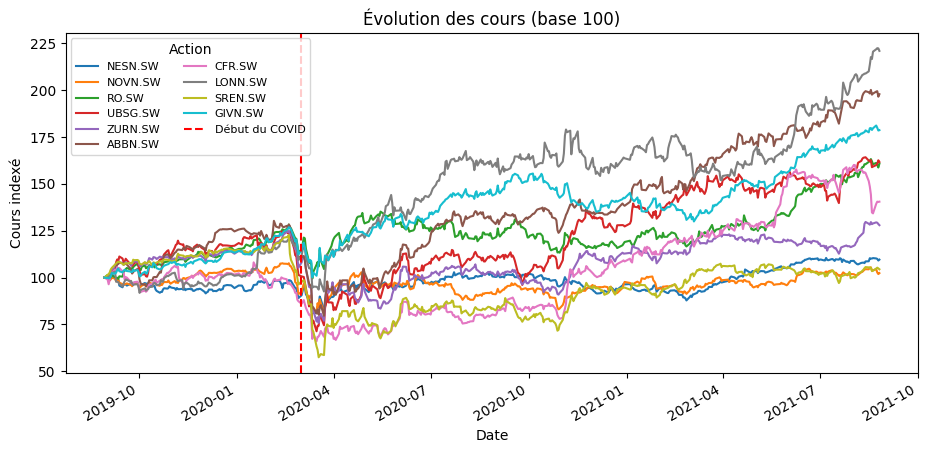

In [3]:
base100 = cours / cours.iloc[0] * 100
ax = base100.plot(title='Évolution des cours (base 100)')
ax.axvline(pd.Timestamp('2020-03-01'), color='red', linestyle='--', label='Début du COVID')
ax.set_ylabel('Cours indexé'); ax.legend(title='Action', ncol=2, fontsize=8)
plt.show()

## 3. Rendements quotidiens

In [4]:
rendements = cours.pct_change().dropna()
rendement_ptf = rendements.dot(poids)   # rendement pondéré du portefeuille

print(f"Nombre de jours : {len(rendement_ptf)}")
print(f"Rendement moyen quotidien : {rendement_ptf.mean():.3%}")
print(f"Volatilité quotidienne :    {rendement_ptf.std():.3%}")

Nombre de jours : 500
Rendement moyen quotidien : 0.081%
Volatilité quotidienne :    1.232%


## 4. Calcul de la VaR

- **Historique** : le 5e centile des rendements observés.
- **Paramétrique** : moyenne + z × écart-type, avec z ≈ -1,645 pour 95 %.

In [5]:
var_hist = np.percentile(rendement_ptf, (1 - CONFIANCE) * 100)
var_param = rendement_ptf.mean() + stats.norm.ppf(1 - CONFIANCE) * rendement_ptf.std()

print(f"VaR historique 95 % :   {var_hist:.2%}  ->  {var_hist * MONTANT:,.0f} CHF")
print(f"VaR paramétrique 95 % : {var_param:.2%}  ->  {var_param * MONTANT:,.0f} CHF")

VaR historique 95 % :   -1.74%  ->  -17,427 CHF
VaR paramétrique 95 % : -1.95%  ->  -19,458 CHF


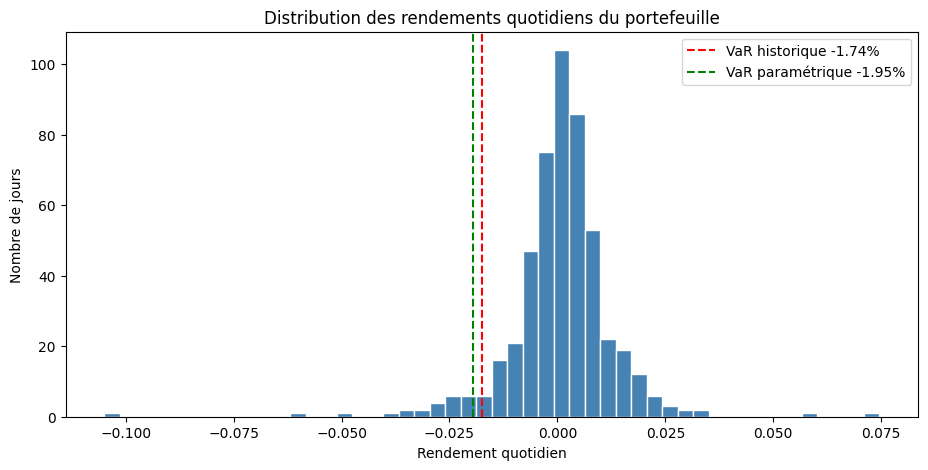

In [6]:
plt.hist(rendement_ptf, bins=50, color='steelblue', edgecolor='white')
plt.axvline(var_hist, color='red', linestyle='--', label=f'VaR historique {var_hist:.2%}')
plt.axvline(var_param, color='green', linestyle='--', label=f'VaR paramétrique {var_param:.2%}')
plt.title('Distribution des rendements quotidiens du portefeuille')
plt.xlabel('Rendement quotidien'); plt.ylabel('Nombre de jours')
plt.legend(); plt.show()

## 5. Vérification

Si la VaR est correcte, la perte devrait la dépasser environ 5 % des jours.

In [7]:
for nom, v in [('historique', var_hist), ('paramétrique', var_param)]:
    depassements = (rendement_ptf < v).mean()
    print(f"VaR {nom:12s} : dépassée {depassements:.1%} des jours (attendu : 5 %)")

VaR historique   : dépassée 5.0% des jours (attendu : 5 %)
VaR paramétrique : dépassée 4.6% des jours (attendu : 5 %)


## 6. Conclusion

- La VaR donne un ordre de grandeur simple de la perte quotidienne « normale » du portefeuille.
- La VaR historique et la VaR paramétrique diffèrent : les rendements réels ne suivent pas une loi normale (les krachs sont plus fréquents que prévu).
- La VaR ne dit **pas** combien on peut perdre lors des 5 % de pires jours : pendant la crise du COVID, certaines pertes ont été bien plus fortes que la VaR.